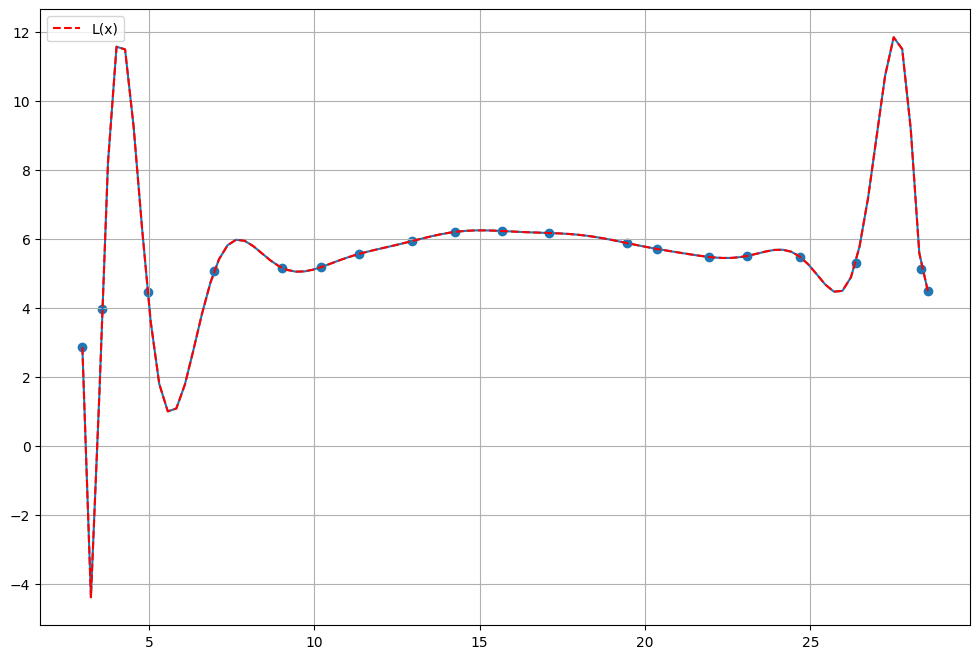

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import barycentric_interpolate


x = np.array([2.983,3.584,4.959,6.972,9.034,10.213,11.342,12.962,14.239,15.663,17.087,19.444,20.376,21.948,23.077,24.697,26.367,28.331,28.552])
y = np.array([2.863,3.971,4.464,5.072,5.159,5.188,5.565,5.942,6.203,6.232,6.174,5.884,5.71,5.478,5.507,5.478,5.304,5.13,4.493])

def lagrange_func(x0, x, y):
  p =np.zeros_like(x0)
  x0=np.array(x0, dtype=np.float64)

  c = []
  for i in range(len(x)):
    ci = 1
    for j in range(len(x)):
      if (i!=j):
        ci*=1.0/((x[i] - x[j]))
    c.append(ci)


  for l in range(len(x0)):
      p1 = 0.0
      p2 = 0.0
      fl = 0

      for i in range(len(x)):
          if np.abs(x0[l] - x[i]) < 1e-14:
              p[l] = y[i]
              fl = 1
              break

      if fl!=1:
          for i in range(len(x)):
              p1 += c[i]/(x0[l] - x[i])*y[i]
              p2 += c[i]/(x0[l] - x[i])
              p[l] =p1/p2

  return p



x0 = np.linspace(2.983, 28.552, 100)

fig, ax = plt.subplots(figsize = (12, 8))
ax.scatter(x, y)

ax.plot(x0, (barycentric_interpolate(x, y , x0)))
ax.plot(x0, (lagrange_func(x0, x, y)), "r--", label = 'L(x)')
plt.legend()
plt.grid()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import spdiags

In [ ]:
def cubic_spline(x, y):
    '''
    N. Melnikov, 2024

    s0, s1, s2, s3 = cubic_spline(x,y)

    Computes the coefficents of a cubic spline
    interpolant through the data points (x,y)

    The spline is defined as the piecewise cubic polynomial

           { Sk(x),    x(k) <= x <= x(k+1),
    S(x) = {
           { 0 ,       otherwise

    The cubic polynomial Sk(x) is given by

    Sk(x)  = sk0 + sk1*(x-x(k)) + sk2*(x-x(k))^2 + sk3*(x-x(k))^3

    The coefficents sk0, sk1, sk2, and sk3 for each of the polynomials
    are returned in the (row) vectors s0, s1, s2, s3, respectively.

    MATLAB source code https://gist.github.com/cmaes/1269709
    contains a bug describing "upper", which has been corrected
    in the Python code below
    '''
    if x.shape != y.shape or x.ndim != 1:
        raise ValueError('inputs x and y must be vectors of equal length')
    Sa=-1
    n = len(x)

    h = x[1:n] - x[0:n-1]
    d = (y[1:n] - y[0:n-1]) / h

    lower = h[1:]

    main = 2 * (h[:-1] + h[1:])
    upper = h[:-1]

    val = 2*h[len(h)-2]+ 3*h[len(h)-1]
    main[-1]=val

    T = spdiags([lower, main, upper], [-1, 0, 1], n-2, n-2).toarray()
    #print (T)
    #print(T[-1][-1])
    rhs = 6 * (d[1:] - d[:-1])
    rhs[0] = rhs[0] - h[-1]*Sa
    #print(rhs)

    m = np.linalg.solve(T, rhs)

    # Use v left and iv right boundary conditions
    m = np.hstack((Sa, m, m[-1]))

    s0 = y[:-1]
    s1 = d - h * (2 * m[:-1] + m[1:]) / 6
    s2 = m / 2
    s3 = (m[1:] - m[:-1]) / (6 * h)

    return s0, s1, s2, s3

In [ ]:
def plot_cubic_spline(x,y, s0, s1, s2, s3):
    '''
    plot_cubic_spline(x,s0,s1,s2,s3)

    plots a cubic spline with knots x
    and coefficents s0, s1, s2, s3
    '''
    n = len(x)
    inner_points = 20

    for i in range(n - 1):
        xx = np.linspace(x[i], x[i + 1], inner_points)
        yy = s0[i] + s1[i] * (xx - x[i]) + s2[i] * (xx - x[i]) ** 2 + s3[i] * (xx - x[i]) ** 3
        plt.plot(xx, yy, 'b--', linewidth=2)

    plt.ylim(-1, 10)
    plt.xlim(x[0], x[-1])
    plt.show()

In [ ]:
def cubic_driver():
    '''
    cubic_driver(n) computes a cubic spline
    interpolant of the runge function

    f(x) = 1/(1 + 25*x^2)

    based on num_points linearly spaced
    points in the interval [-1,1]
    '''
    x = np.linspace(3.584, 28.552, 17)
    y = np.array([3.971,4.464,5.072,5.159,5.188,5.565,5.942,6.203,6.232,6.174,5.884,5.71,5.478,5.507,5.478,5.304,4.493])


    s0, s1, s2, s3 = cubic_spline(x, y)


    xx = np.array([3.584,4.959,6.972,9.034,10.213,11.342,12.962,14.239,15.663,17.087,19.444,20.376,21.948,23.077,24.697,26.367,28.552])
    yy = np.array([3.971,4.464,5.072,5.159,5.188,5.565,5.942,6.203,6.232,6.174,5.884,5.71,5.478,5.507,5.478,5.304,4.493])
    plt.scatter(xx, yy, color = 'r')
    plt.ylabel("K(x)")
    plt.grid()


    plot_cubic_spline(x,y, s0, s1, s2, s3)


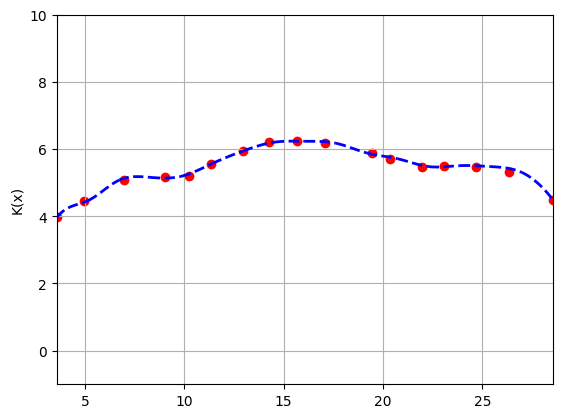

In [ ]:
cubic_driver()



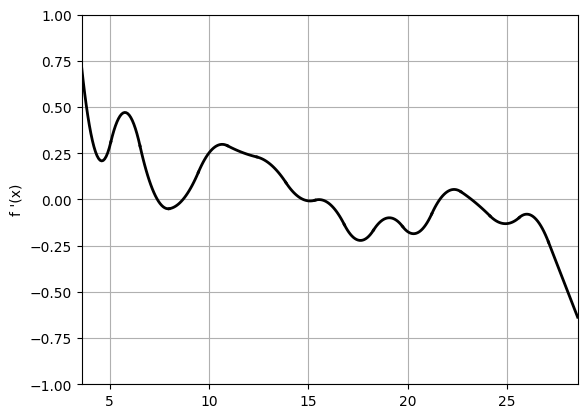

In [ ]:
def dif1(x,y, s0, s1, s2, s3):
  n = len(x)
  inner_points = 20

  for i in range(n - 1):
      xx = np.linspace(x[i], x[i + 1], inner_points)
      yy = s1[i] + 2 * s2[i] * (xx - x[i])  + 3 * s3[i] * (xx - x[i]) ** 2
      plt.plot(xx, yy, 'k', linewidth=2)


  plt.ylim(-1, 1)
  plt.xlim(x[0], x[-1])
  plt.ylabel("f '(x)")
  plt.grid()


x = np.linspace(3.584, 28.552, 18)
y = np.array([3.971,4.464,5.072,5.159,5.188,5.565,5.942,6.203,6.232,6.174,5.884,5.71,5.478,5.507,5.478,5.304,5.13,4.493])

s0, s1, s2, s3 = cubic_spline(x, y)
dif1(x,y, s0, s1, s2, s3)


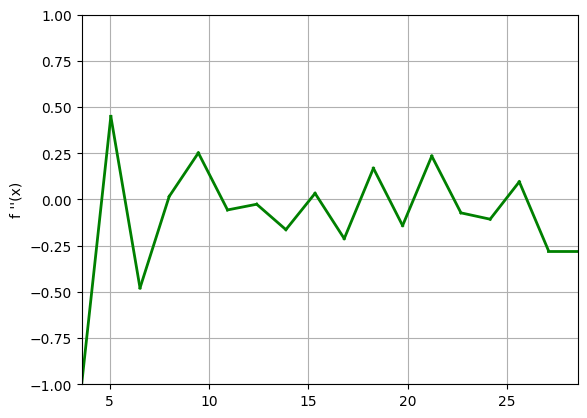

In [ ]:
def dif2(x,y, s0, s1, s2, s3):
  n = len(x)
  inner_points = 20

  for i in range(n - 1):
      xx = np.linspace(x[i], x[i + 1], inner_points)
      yy = 2 * s2[i] + 3 * 2 * s3[i] * (xx - x[i])
      plt.plot(xx, yy, 'g', linewidth=2)


  plt.ylim(-1, 1)
  plt.xlim(x[0], x[-1])
  plt.ylabel("f ''(x)")
  plt.grid()


x = np.linspace(3.584, 28.552, 18)
y = np.array([3.971,4.464,5.072,5.159,5.188,5.565,5.942,6.203,6.232,6.174,5.884,5.71,5.478,5.507,5.478,5.304,5.13,4.493])

s0, s1, s2, s3 = cubic_spline(x, y)
dif2(x,y, s0, s1, s2, s3)

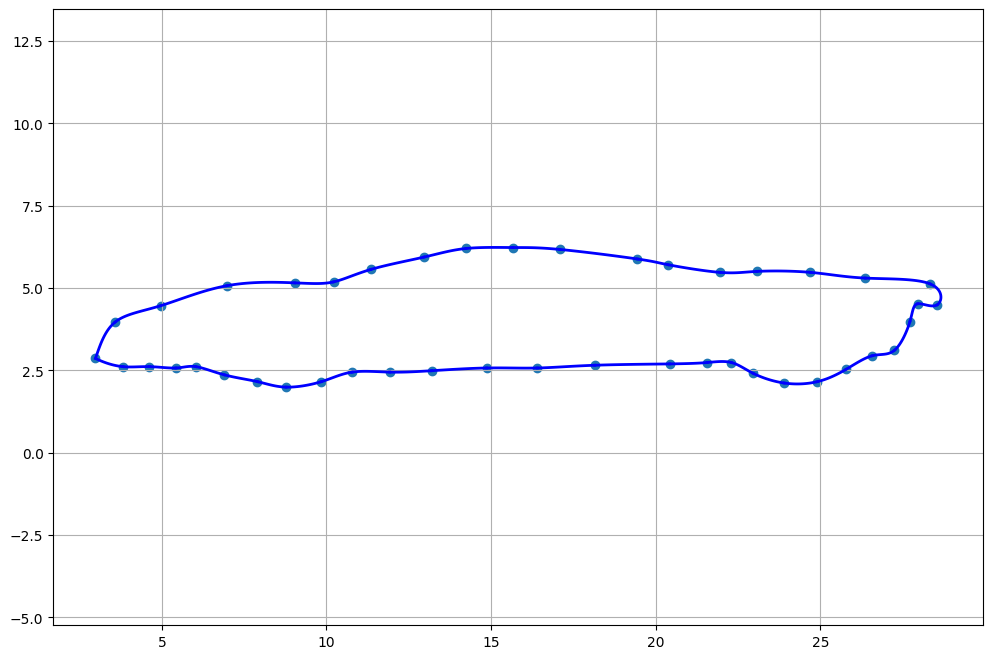

In [ ]:

def plot_parametrical_spline(t, s0x, s1x, s2x, s3x, s0y, s1y, s2y, s3y ):
    inner_points=20
    plt.figure(figsize=(12, 8))

    for i in range(len(t) - 1):
        tk = np.linspace(t[i], t[i+1], inner_points)
        delta_t = tk - t[i]
        sx_p = s0x[i] + s1x[i] * delta_t + s2x[i] * delta_t**2 + s3x[i] * delta_t**3
        sy_p = s0y[i] + s1y[i] * delta_t + s2y[i] * delta_t**2 + s3y[i] * delta_t**3
        plt.plot(sx_p , sy_p , 'b-', linewidth=2)


    x_t = s0x
    y_t = s0y


    plt.scatter(x_t,y_t)
    plt.axis('equal')
    plt.grid()






x1= np.array([2.983,3.584,4.959,6.972,9.034,10.213,11.342,12.962,14.239,15.663,17.087,19.444,20.376,21.948,23.077,24.697,26.367,28.331,28.552])
y1 = np.array([2.863,3.971,4.464,5.072,5.159,5.188,5.565,5.942,6.203,6.232,6.174,5.884,5.71,5.478,5.507,5.478,5.304,5.13,4.493])
x2 = np.array([2.983,3.817,4.621,5.424,6.027,6.897,7.902,8.772,9.844,10.781,11.92,13.192,14.866,16.406,18.147,20.424,21.562,22.299,22.969,23.906,24.911,25.781,26.585,27.254,27.723,27.958])
y2 = np.array([2.863,2.614,2.614,2.573,2.614,2.365,2.158,1.992,2.158,2.448,2.448,2.49,2.573,2.573,2.656,2.697,2.739,2.739,2.407,2.116,2.158,2.531,2.946,3.112,3.983,4.523])
x_full = np.append(x1, x2[::-1])
y_full = np.append(y1, y2[::-1])

t = np.linspace(0, np.pi, len(x_full))

s0x, s1x, s2x, s3x = cubic_spline(t, x_full)
s0y, s1y, s2y, s3y = cubic_spline(t, y_full)
plot_parametrical_spline(t, s0x, s1x, s2x, s3x, s0y, s1y, s2y, s3y)


